# CSE366 – Submission 2: Pretrained Models (With and Without Fine-Tuning)
**Project:** PCB-LiteX – PCB Defect Classification  
**Dataset:** PCB-Defect (Mendeley Data) – 6 defect classes

## What the roadmap asks for in Submission 2
| Requirement | Where it is done |
|---|---|
| At least 3 pretrained CNN architectures | ResNet-50, EfficientNet-B0, MobileNetV2 (Section 5) |
| With and without fine-tuning | Feature extraction (frozen) and Fine-tuning (all layers) (Section 5) |
| 30–50 epochs | 40 epochs for every run |
| If overfitting or underfitting occurs, fix it | Section 6 |
| Accuracy curve (train vs validation) | Section 8, every run |
| Loss curve (train vs validation) | Section 8, every run |
| Classification report (precision, recall, F1 per class) | Section 8, every run |
| Confusion matrix on the test set | Section 8, every run |
| Accuracy, precision, recall, F1 | Sections 7 and 9 |
| Training and testing time | Sections 7 and 9 |

**Important:** use a GPU (Runtime → Change runtime type → T4 GPU) and run all cells before pushing to GitHub.

# 0. Import libraries and settings

In [ ]:
import os
import json
import time
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image

import torch
import torch.nn as nn
import torchvision.models as models
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_recall_fscore_support
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

Image.MAX_IMAGE_PIXELS = None   # the PCB board images are very large

# ----- settings -----
SEED = 42
IMG_SIZE = 224        # input size for the pretrained networks
EPOCHS = 40           # roadmap: 30 to 50 epochs
BATCH_SIZE = 32
CONTEXT = 3.0         # patch side = 3 x defect box side

MODEL_NAMES = ["resnet50", "efficientnet_b0", "mobilenet_v2"]
MODES = ["feature_extraction", "fine_tuning"]

# fix the random seeds so results can be repeated
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
if device == "cpu":
    print("WARNING: no GPU found. Training will be very slow.")

# folder where plots and tables are saved (used for the download at the end)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

Using device: cuda


# 1. Dataset
### 1.1 Download the dataset
Source: https://data.mendeley.com/datasets/vdj74sngvn/1  
If the automatic download does not work, download the ZIP file yourself and upload it when Colab asks.

In [ ]:
DATA_DIR = Path("pcb_defect_data")
DATA_DIR.mkdir(exist_ok=True)
ZIP_PATH = DATA_DIR / "pcb_defect_v1.zip"
RAW_DIR = DATA_DIR / "raw"
URL = "https://data.mendeley.com/public-api/zip/vdj74sngvn/download/1"

if RAW_DIR.exists():
    print("Dataset already extracted.")
else:
    # step 1: try to download automatically
    try:
        print("Downloading dataset...")
        response = requests.get(URL, stream=True, timeout=180)
        response.raise_for_status()
        with open(ZIP_PATH, "wb") as f:
            for chunk in response.iter_content(1024 * 1024):
                f.write(chunk)
    except Exception as e:
        print("Automatic download failed:", e)

    # step 2: if it failed, ask the user to upload the ZIP file
    if not (ZIP_PATH.exists() and zipfile.is_zipfile(ZIP_PATH)):
        from google.colab import files
        print("Please upload the dataset ZIP file now.")
        uploaded = files.upload()
        uploaded_name = list(uploaded.keys())[0]
        os.replace(uploaded_name, ZIP_PATH)

    # step 3: extract the ZIP file
    RAW_DIR.mkdir()
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_DIR)

    # step 4: extract zip files inside the zip file (if there are any)
    for i in range(3):
        inner_zips = list(RAW_DIR.rglob("*.zip"))
        for inner in inner_zips:
            with zipfile.ZipFile(inner) as z:
                z.extractall(inner.parent)
            inner.unlink()
    print("Dataset extracted.")

Dataset extracted.


### 1.2 Read the annotation file (COCO format)

In [ ]:
# find the COCO json file
coco = None
for json_path in RAW_DIR.rglob("*.json"):
    try:
        with open(json_path) as f:
            data = json.load(f)
        if "images" in data and "annotations" in data and "categories" in data:
            coco = data
            print("Annotation file:", json_path)
            break
    except Exception:
        continue
assert coco is not None, "No COCO annotation file found"

# find all image files
image_paths = {}
for p in RAW_DIR.rglob("*"):
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        image_paths[p.name] = p
print("Image files found:", len(image_paths))

# make lookup tables
category_names = {}
for c in coco["categories"]:
    category_names[c["id"]] = c["name"]

image_files = {}
for im in coco["images"]:
    image_files[im["id"]] = im["file_name"]

# put every defect (bounding box) in a table
rows = []
for a in coco["annotations"]:
    file_name = Path(image_files[a["image_id"]]).name
    if file_name not in image_paths:
        continue
    rows.append({
        "ann_id": a["id"],
        "board": a["image_id"],
        "label": category_names[a["category_id"]],
        "x": a["bbox"][0],
        "y": a["bbox"][1],
        "w": a["bbox"][2],
        "h": a["bbox"][3],
        "path": str(image_paths[file_name]),
    })
ann = pd.DataFrame(rows)

# only use classes that really have boxes (the dataset has one empty placeholder class)
CLASSES = sorted(ann["label"].unique())
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {}
for i in range(NUM_CLASSES):
    CLASS_TO_IDX[CLASSES[i]] = i

print("Classes:", CLASSES)
print("Number of boards:", ann["board"].nunique())
print("Number of defects:", len(ann))

Annotation file: pcb_defect_data/raw/PCB-Defect An Annotated Dataset for Surface Defect/PCB_Defect/annotation/_annotations.coco.json
Image files found: 230
Classes: ['missing_pad', 'mouse_bite', 'open_circuit', 'short', 'spur', 'spurious_copper']
Number of boards: 230
Number of defects: 1704


### 1.3 Cut one patch for every defect
The roadmap needs classification results, so every defect box is cut out as a square image (patch) and given its defect class as the label.
The patch is 3 times larger than the box, so the network can also see the copper around the defect.

In [ ]:
PATCH_DIR = Path("patches")
META_FILE = PATCH_DIR / "meta.csv"

def crop_patch(board_image, x, y, w, h):
    """Cut a square patch around the defect box."""
    center_x = x + w / 2
    center_y = y + h / 2
    side = max(w, h) * CONTEXT
    side = max(side, 96)                                   # not too small
    side = min(side, board_image.width, board_image.height)  # not bigger than the board
    left = center_x - side / 2
    top = center_y - side / 2
    left = min(max(left, 0), board_image.width - side)     # keep the window inside the board
    top = min(max(top, 0), board_image.height - side)
    return board_image.crop((int(left), int(top), int(left + side), int(top + side)))

if META_FILE.exists():
    meta = pd.read_csv(META_FILE)
    print("Patches already created.")
else:
    for c in CLASSES:
        (PATCH_DIR / c).mkdir(parents=True, exist_ok=True)

    meta_rows = []
    for board_id, group in ann.groupby("board"):
        board_image = Image.open(group.iloc[0]["path"]).convert("RGB")
        for index, row in group.iterrows():
            if row["w"] < 4 or row["h"] < 4:      # skip very tiny boxes
                continue
            patch = crop_patch(board_image, row["x"], row["y"], row["w"], row["h"])
            patch = patch.resize((IMG_SIZE, IMG_SIZE))
            file_path = PATCH_DIR / row["label"] / ("b" + str(board_id) + "_a" + str(row["ann_id"]) + ".png")
            patch.save(file_path)
            meta_rows.append({"path": str(file_path), "label": row["label"], "board": int(board_id)})

    meta = pd.DataFrame(meta_rows)
    meta.to_csv(META_FILE, index=False)
    print("Patches created.")

print("Total patches:", len(meta))
print(meta["label"].value_counts())

Patches created.
Total patches: 1704
label
mouse_bite         356
spur               296
missing_pad        276
open_circuit       276
short              254
spurious_copper    246
Name: count, dtype: int64


# 2. Train / validation / test split
The split is done **by board**: all patches of one board go into the same set. Otherwise very similar patches would be in both train and test (data leakage).
About 72% train, 14% validation and 14% test.

In [ ]:
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
fold_indices = []
for train_idx, test_idx in splitter.split(meta, meta["label"], groups=meta["board"]):
    fold_indices.append(test_idx)

meta["split"] = "train"
meta.loc[meta.index[fold_indices[0]], "split"] = "test"
meta.loc[meta.index[fold_indices[1]], "split"] = "val"

train_df = meta[meta["split"] == "train"].reset_index(drop=True)
val_df = meta[meta["split"] == "val"].reset_index(drop=True)
test_df = meta[meta["split"] == "test"].reset_index(drop=True)

# check: no board is in two sets
train_boards = set(train_df["board"])
val_boards = set(val_df["board"])
test_boards = set(test_df["board"])
assert len(train_boards & val_boards) == 0
assert len(train_boards & test_boards) == 0
assert len(val_boards & test_boards) == 0
print("No board is shared between train, validation and test.")

print("Train patches:", len(train_df))
print("Validation patches:", len(val_df))
print("Test patches:", len(test_df))
print()
print(meta.groupby(["label", "split"]).size().unstack()[["train", "val", "test"]])

No board is shared between train, validation and test.
Train patches: 1226
Validation patches: 253
Test patches: 225

split            train  val  test
label                            
missing_pad        198   40    38
mouse_bite         263   48    45
open_circuit       197   47    32
short              185   36    33
spur               206   46    44
spurious_copper    177   36    33


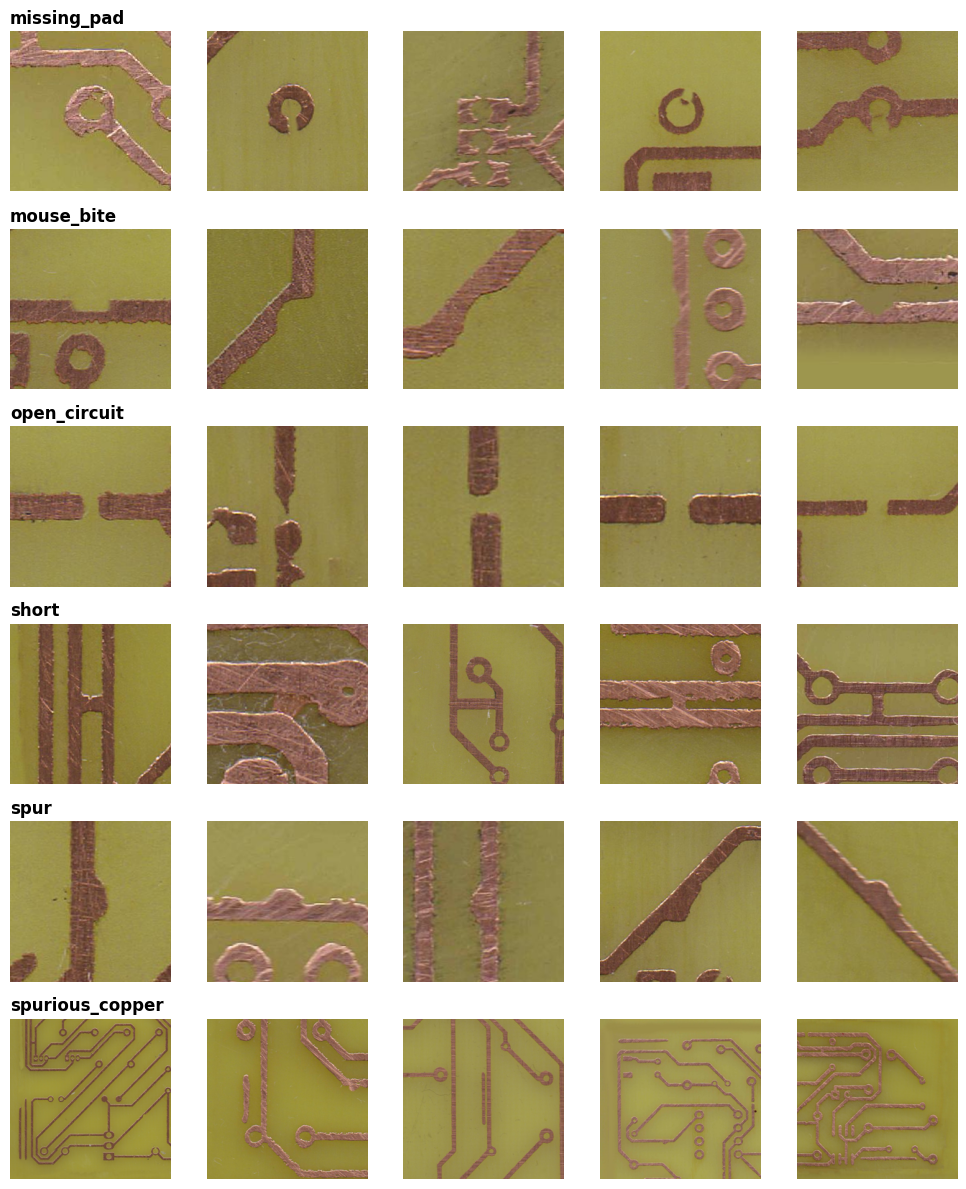

In [ ]:
# show 5 sample patches per class
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(10, 2 * NUM_CLASSES))
for r in range(NUM_CLASSES):
    class_name = CLASSES[r]
    samples = train_df[train_df["label"] == class_name].sample(5, replace=True, random_state=1)
    for k in range(5):
        axes[r, k].imshow(Image.open(samples.iloc[k]["path"]))
        axes[r, k].axis("off")
    axes[r, 0].set_title(class_name, loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "sample_patches.png", dpi=100)
plt.show()

# 3. Data loading
- **Training images:** random horizontal flip, random vertical flip and a small colour change (a defect is still the same defect after a flip).
- **Validation and test images:** only converted to tensors and normalised with the ImageNet mean and std (the pretrained models were trained with these values).

In [ ]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

class PatchDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.paths = dataframe["path"].tolist()
        self.labels = []
        for name in dataframe["label"]:
            self.labels.append(CLASS_TO_IDX[name])
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert("RGB")
        image = self.transform(image)
        return image, self.labels[index]

train_loader = DataLoader(PatchDataset(train_df, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(PatchDataset(val_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(PatchDataset(test_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Batches per epoch (train / val / test):", len(train_loader), len(val_loader), len(test_loader))

Batches per epoch (train / val / test): 39 8 8


# 4. Functions: model, training, validation and testing

### The two modes
| | Without fine-tuning (feature extraction) | With fine-tuning |
|---|---|---|
| Pretrained layers | frozen (not changed) | trained together with the new layer |
| New last layer | trained | trained |
| Learning rate | 0.001 | 0.0001 (small, so pretrained weights are not destroyed) |

Both modes use: AdamW optimizer, cosine learning-rate schedule, cross-entropy loss, 40 epochs.
After training, the weights of the **best epoch (lowest validation loss)** are restored.

In [ ]:
def build_model(model_name, mode, dropout=0.4):
    """Load a pretrained model and put a new last layer for our 6 classes."""
    if model_name == "resnet50":
        model = models.resnet50(weights="IMAGENET1K_V2")
    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(weights="IMAGENET1K_V1")
    elif model_name == "mobilenet_v2":
        model = models.mobilenet_v2(weights="IMAGENET1K_V1")

    # WITHOUT fine-tuning: freeze all pretrained layers
    if mode == "feature_extraction":
        for parameter in model.parameters():
            parameter.requires_grad = False

    # replace the last layer (new layers are trainable by default)
    if model_name == "resnet50":
        in_features = model.fc.in_features
        model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_features, NUM_CLASSES))
    else:
        in_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(in_features, NUM_CLASSES))

    return model.to(device)


def validate(model, loader):
    """Go through a data loader without training. Returns loss, accuracy, predictions and true labels."""
    model.eval()
    loss_function = nn.CrossEntropyLoss(reduction="sum")
    total_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            total_loss = total_loss + loss_function(outputs, labels).item()
            predictions = outputs.argmax(dim=1)
            all_predictions.extend(predictions.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    all_predictions = np.array(all_predictions)
    all_labels = np.array(all_labels)
    average_loss = total_loss / len(all_labels)
    accuracy = (all_predictions == all_labels).mean()
    return average_loss, accuracy, all_predictions, all_labels


def train_model(model_name, mode, dropout=0.4, weight_decay=1e-4, lr_scale=1.0):
    """Train one model for EPOCHS epochs and return everything we need later."""
    model = build_model(model_name, mode, dropout)

    # learning rate depends on the mode
    if mode == "feature_extraction":
        learning_rate = 1e-3 * lr_scale
    else:
        learning_rate = 1e-4 * lr_scale

    # only give the trainable parameters to the optimizer
    trainable_parameters = []
    for parameter in model.parameters():
        if parameter.requires_grad:
            trainable_parameters.append(parameter)

    optimizer = torch.optim.AdamW(trainable_parameters, lr=learning_rate, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    loss_function = nn.CrossEntropyLoss()

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss = 999999.0
    best_epoch = 0
    best_weights = None

    start_time = time.time()

    for epoch in range(EPOCHS):
        # ----- training part -----
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss = running_loss + loss.item() * len(labels)
            correct = correct + (outputs.argmax(dim=1) == labels).sum().item()
            total = total + len(labels)

        scheduler.step()
        train_loss = running_loss / total
        train_acc = correct / total

        # ----- validation part -----
        val_loss, val_acc, _, _ = validate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        # remember the best epoch
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_weights = {}
            for key, value in model.state_dict().items():
                best_weights[key] = value.cpu().clone()

        if epoch == 0 or (epoch + 1) % 5 == 0:
            print("  epoch %2d/%d | train loss %.3f acc %.3f | val loss %.3f acc %.3f" %
                  (epoch + 1, EPOCHS, train_loss, train_acc, val_loss, val_acc))

    train_time = time.time() - start_time

    # go back to the best epoch
    model.load_state_dict(best_weights)

    result = {
        "model_name": model_name,
        "mode": mode,
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "train_time": train_time,
        "settings": "dropout=%s, weight_decay=%s, lr_scale=%s" % (dropout, weight_decay, lr_scale),
    }
    return result

# 5. Train 3 models × 2 modes (6 runs, 40 epochs each)
- **ResNet-50**, **EfficientNet-B0**, **MobileNetV2** (ImageNet weights)
- each one **without fine-tuning** (feature extraction) and **with fine-tuning**

On a free Colab T4 GPU this takes about 20–40 minutes.

In [ ]:
results = {}

for model_name in MODEL_NAMES:
    for mode in MODES:
        run_name = model_name + "_" + mode
        print("=== Training:", run_name, "===")
        results[run_name] = train_model(model_name, mode)
        print("Finished. Best epoch:", results[run_name]["best_epoch"] + 1,
              "| Training time: %.1f s" % results[run_name]["train_time"])
        print()

=== Training: resnet50_feature_extraction ===
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 235MB/s]


  epoch  1/40 | train loss 1.562 acc 0.383 | val loss 1.388 acc 0.478
  epoch  5/40 | train loss 1.023 acc 0.644 | val loss 1.104 acc 0.585
  epoch 10/40 | train loss 0.886 acc 0.680 | val loss 1.013 acc 0.621
  epoch 15/40 | train loss 0.805 acc 0.726 | val loss 0.965 acc 0.617
  epoch 20/40 | train loss 0.767 acc 0.736 | val loss 0.956 acc 0.648
  epoch 25/40 | train loss 0.779 acc 0.726 | val loss 0.939 acc 0.644
  epoch 30/40 | train loss 0.744 acc 0.737 | val loss 0.938 acc 0.640
  epoch 35/40 | train loss 0.725 acc 0.746 | val loss 0.926 acc 0.640
  epoch 40/40 | train loss 0.737 acc 0.730 | val loss 0.928 acc 0.652
Finished. Best epoch: 37 | Training time: 72.9 s

=== Training: resnet50_fine_tuning ===
  epoch  1/40 | train loss 1.551 acc 0.417 | val loss 1.144 acc 0.688
  epoch  5/40 | train loss 0.102 acc 0.966 | val loss 0.219 acc 0.937
  epoch 10/40 | train loss 0.035 acc 0.991 | val loss 0.247 acc 0.945
  epoch 15/40 | train loss 0.005 acc 0.999 | val loss 0.126 acc 0.964
 

100%|██████████| 20.5M/20.5M [00:00<00:00, 161MB/s]


  epoch  1/40 | train loss 1.535 acc 0.388 | val loss 1.294 acc 0.514
  epoch  5/40 | train loss 1.052 acc 0.623 | val loss 1.028 acc 0.625
  epoch 10/40 | train loss 0.910 acc 0.660 | val loss 0.964 acc 0.625
  epoch 15/40 | train loss 0.887 acc 0.674 | val loss 0.936 acc 0.625
  epoch 20/40 | train loss 0.828 acc 0.695 | val loss 0.921 acc 0.640
  epoch 25/40 | train loss 0.836 acc 0.700 | val loss 0.924 acc 0.636
  epoch 30/40 | train loss 0.831 acc 0.677 | val loss 0.931 acc 0.636
  epoch 35/40 | train loss 0.848 acc 0.690 | val loss 0.920 acc 0.632
  epoch 40/40 | train loss 0.828 acc 0.675 | val loss 0.920 acc 0.636
Finished. Best epoch: 27 | Training time: 71.0 s

=== Training: efficientnet_b0_fine_tuning ===
  epoch  1/40 | train loss 1.596 acc 0.368 | val loss 1.305 acc 0.597
  epoch  5/40 | train loss 0.305 acc 0.903 | val loss 0.260 acc 0.925
  epoch 10/40 | train loss 0.088 acc 0.977 | val loss 0.178 acc 0.953
  epoch 15/40 | train loss 0.031 acc 0.993 | val loss 0.163 acc 

100%|██████████| 13.6M/13.6M [00:00<00:00, 134MB/s]


  epoch  1/40 | train loss 1.560 acc 0.342 | val loss 1.249 acc 0.506
  epoch  5/40 | train loss 1.006 acc 0.605 | val loss 0.997 acc 0.589
  epoch 10/40 | train loss 0.888 acc 0.647 | val loss 0.992 acc 0.625
  epoch 15/40 | train loss 0.839 acc 0.684 | val loss 0.885 acc 0.640
  epoch 20/40 | train loss 0.801 acc 0.691 | val loss 0.895 acc 0.660
  epoch 25/40 | train loss 0.812 acc 0.692 | val loss 0.880 acc 0.672
  epoch 30/40 | train loss 0.781 acc 0.700 | val loss 0.902 acc 0.664
  epoch 35/40 | train loss 0.746 acc 0.706 | val loss 0.882 acc 0.664
  epoch 40/40 | train loss 0.766 acc 0.714 | val loss 0.879 acc 0.676
Finished. Best epoch: 19 | Training time: 71.2 s

=== Training: mobilenet_v2_fine_tuning ===
  epoch  1/40 | train loss 1.260 acc 0.511 | val loss 0.856 acc 0.684
  epoch  5/40 | train loss 0.117 acc 0.967 | val loss 0.215 acc 0.945
  epoch 10/40 | train loss 0.023 acc 0.998 | val loss 0.188 acc 0.949
  epoch 15/40 | train loss 0.014 acc 0.998 | val loss 0.159 acc 0.9

# 6. Overfitting and underfitting check, and fix
The roadmap says: *"If overfitting or underfitting occurs, fix it."*

For every run we look at the best epoch:
- **Overfitting** → train accuracy is more than 0.10 higher than validation accuracy.
- **Underfitting** → both train accuracy and validation accuracy are below 0.70.

If a problem is found, the model is trained **once more** with a fix:

| Problem | Fix |
|---|---|
| Overfitting | dropout 0.4 → 0.6, weight decay 1e-4 → 1e-2, learning rate × 0.5 |
| Underfitting | dropout 0.4 → 0.2, weight decay 1e-4 → 1e-5, learning rate × 3 |

The better version (lower validation loss) is kept. The test set is **not** used for this decision.

In [ ]:
def check_fitting(result):
    """Look at the best epoch and say if the model overfits or underfits."""
    best = result["best_epoch"]
    train_acc = result["history"]["train_acc"][best]
    val_acc = result["history"]["val_acc"][best]
    gap = train_acc - val_acc

    if gap > 0.10:
        problem = "overfitting"
    elif train_acc < 0.70 and val_acc < 0.70:
        problem = "underfitting"
    else:
        problem = "none"
    return problem, train_acc, val_acc, gap


fit_rows = []

for run_name in list(results.keys()):
    old_result = results[run_name]
    problem, train_acc, val_acc, gap = check_fitting(old_result)
    action = "nothing to fix"
    new_val_acc = None

    if problem == "overfitting":
        print(run_name, "-> overfitting found. Training again with more regularisation...")
        new_result = train_model(old_result["model_name"], old_result["mode"],
                                 dropout=0.6, weight_decay=1e-2, lr_scale=0.5)
    elif problem == "underfitting":
        print(run_name, "-> underfitting found. Training again with a higher learning rate...")
        new_result = train_model(old_result["model_name"], old_result["mode"],
                                 dropout=0.2, weight_decay=1e-5, lr_scale=3.0)
    else:
        print(run_name, "-> no problem found.")
        new_result = None

    if new_result is not None:
        new_val_acc = new_result["history"]["val_acc"][new_result["best_epoch"]]
        if new_result["best_val_loss"] < old_result["best_val_loss"]:
            results[run_name] = new_result
            action = "fixed version kept"
        else:
            action = "fixed version was not better, original kept"

    fit_rows.append({
        "Run": run_name,
        "Train acc": round(train_acc, 3),
        "Val acc": round(val_acc, 3),
        "Gap": round(gap, 3),
        "Problem": problem,
        "Action": action,
        "Val acc after fix": None if new_val_acc is None else round(new_val_acc, 3),
    })

fit_table = pd.DataFrame(fit_rows)
fit_table.to_csv(RESULTS_DIR / "overfit_underfit_check.csv", index=False)
fit_table

resnet50_feature_extraction -> no problem found.
resnet50_fine_tuning -> no problem found.
efficientnet_b0_feature_extraction -> underfitting found. Training again with a higher learning rate...
  epoch  1/40 | train loss 1.360 acc 0.458 | val loss 1.077 acc 0.577
  epoch  5/40 | train loss 0.881 acc 0.661 | val loss 0.932 acc 0.636
  epoch 10/40 | train loss 0.793 acc 0.691 | val loss 0.934 acc 0.640
  epoch 15/40 | train loss 0.769 acc 0.716 | val loss 0.923 acc 0.652
  epoch 20/40 | train loss 0.715 acc 0.719 | val loss 0.904 acc 0.644
  epoch 25/40 | train loss 0.717 acc 0.731 | val loss 0.924 acc 0.636
  epoch 30/40 | train loss 0.675 acc 0.750 | val loss 0.917 acc 0.644
  epoch 35/40 | train loss 0.692 acc 0.738 | val loss 0.914 acc 0.636
  epoch 40/40 | train loss 0.648 acc 0.759 | val loss 0.910 acc 0.656
efficientnet_b0_fine_tuning -> no problem found.
mobilenet_v2_feature_extraction -> underfitting found. Training again with a higher learning rate...
  epoch  1/40 | train los

,Run,Train acc,Val acc,Gap,Problem,Action,Val acc after fix
0,resnet50_feature_extraction,0.733,0.660,0.073,none,nothing to fix,NaN
1,resnet50_fine_tuning,0.999,0.964,0.035,none,nothing to fix,NaN
2,efficientnet_b0_feature_extraction,0.692,0.644,0.047,underfitting,fixed version kept,0.668
3,efficientnet_b0_fine_tuning,0.993,0.964,0.029,none,nothing to fix,NaN
4,mobilenet_v2_feature_extraction,0.661,0.668,-0.007,underfitting,fixed version kept,0.692
5,mobilenet_v2_fine_tuning,0.999,0.964,0.035,none,nothing to fix,NaN


# 7. Test the final models
Every final model is tested **once** on the test set. We measure accuracy, precision, recall, F1 (macro average over the 6 classes), the confusion matrix and the **testing time**.

In [ ]:
test_results = {}

for run_name in results.keys():
    result = results[run_name]
    model = result["model"]

    # one warm-up pass so the timing is fair (GPU start-up is not counted)
    validate(model, test_loader)

    if device == "cuda":
        torch.cuda.synchronize()
    start_time = time.time()
    _, accuracy, predictions, true_labels = validate(model, test_loader)
    if device == "cuda":
        torch.cuda.synchronize()
    test_time = time.time() - start_time

    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels, predictions, average="macro", zero_division=0)

    label_list = list(range(NUM_CLASSES))
    cm = confusion_matrix(true_labels, predictions, labels=label_list)
    report = classification_report(true_labels, predictions, labels=label_list,
                                   target_names=CLASSES, digits=3, zero_division=0)

    test_results[run_name] = {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "test_time": test_time,
        "ms_per_image": 1000 * test_time / len(true_labels),
        "cm": cm,
        "report": report,
    }
    print("%-35s accuracy %.4f | precision %.4f | recall %.4f | F1 %.4f" %
          (run_name, accuracy, precision, recall, f1))

resnet50_feature_extraction         accuracy 0.7378 | precision 0.7447 | recall 0.7566 | F1 0.7472
resnet50_fine_tuning                accuracy 0.9644 | precision 0.9660 | recall 0.9683 | F1 0.9665
efficientnet_b0_feature_extraction  accuracy 0.6844 | precision 0.6998 | recall 0.7033 | F1 0.6955
efficientnet_b0_fine_tuning         accuracy 0.9644 | precision 0.9668 | recall 0.9681 | F1 0.9674
mobilenet_v2_feature_extraction     accuracy 0.7333 | precision 0.7520 | recall 0.7471 | F1 0.7440
mobilenet_v2_fine_tuning            accuracy 0.9556 | precision 0.9594 | recall 0.9600 | F1 0.9596


# 8. Results for every model and mode
For each of the 6 runs: **accuracy curve** (train vs validation), **loss curve** (train vs validation), **confusion matrix** (test set) and **classification report** (precision, recall, F1 per class).
The grey dashed line is the best epoch that was restored.

In [ ]:
def plot_accuracy_curve(result, title):
    history = result["history"]
    epochs = range(1, len(history["train_acc"]) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs, history["train_acc"], label="Train accuracy")
    plt.plot(epochs, history["val_acc"], label="Validation accuracy")
    plt.axvline(result["best_epoch"] + 1, color="grey", linestyle="--", label="Best epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Accuracy curve - " + title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / (title.replace(" ", "_").replace("|", "") + "_accuracy.png"), dpi=100)
    plt.show()


def plot_loss_curve(result, title):
    history = result["history"]
    epochs = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs, history["train_loss"], label="Train loss")
    plt.plot(epochs, history["val_loss"], label="Validation loss")
    plt.axvline(result["best_epoch"] + 1, color="grey", linestyle="--", label="Best epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Loss curve - " + title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / (title.replace(" ", "_").replace("|", "") + "_loss.png"), dpi=100)
    plt.show()


def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(NUM_CLASSES), CLASSES, rotation=45, ha="right")
    plt.yticks(range(NUM_CLASSES), CLASSES)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cm[i, j] > cm.max() / 2:
                text_color = "white"
            else:
                text_color = "black"
            plt.text(j, i, cm[i, j], ha="center", va="center", color=text_color)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title("Confusion matrix (test set) - " + title)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / (title.replace(" ", "_").replace("|", "") + "_confusion_matrix.png"), dpi=100)
    plt.show()

####################################################################################################
MODEL: resnet50    MODE: feature_extraction
Settings: dropout=0.4, weight_decay=0.0001, lr_scale=1.0 | Best epoch: 37 of 40
####################################################################################################


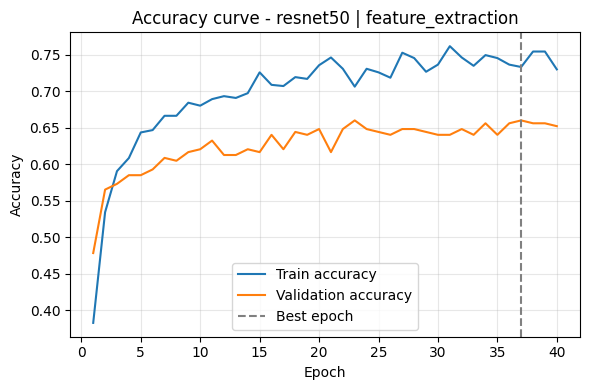

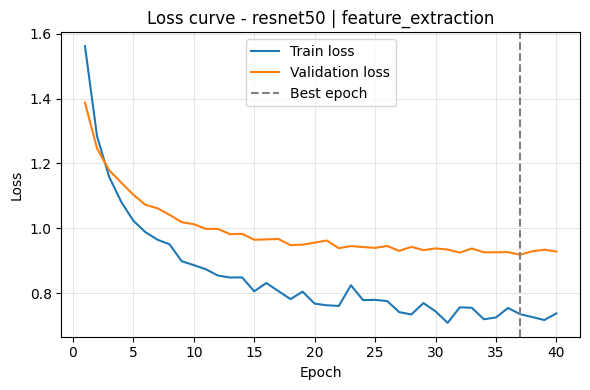

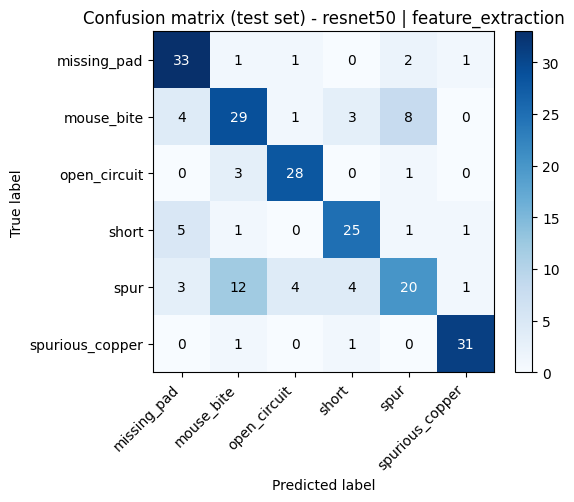

Classification report (test set):
                 precision    recall  f1-score   support

    missing_pad      0.733     0.868     0.795        38
     mouse_bite      0.617     0.644     0.630        45
   open_circuit      0.824     0.875     0.848        32
          short      0.758     0.758     0.758        33
           spur      0.625     0.455     0.526        44
spurious_copper      0.912     0.939     0.925        33

       accuracy                          0.738       225
      macro avg      0.745     0.757     0.747       225
   weighted avg      0.731     0.738     0.731       225

Accuracy  : 0.7378
Precision : 0.7447 (macro)
Recall    : 0.7566 (macro)
F1-score  : 0.7472 (macro)
Training time: 72.9 seconds
Testing time : 0.291 seconds (1.29 ms per image)

####################################################################################################
MODEL: resnet50    MODE: fine_tuning
Settings: dropout=0.4, weight_decay=0.0001, lr_scale=1.0 | Best epoch: 15 of 

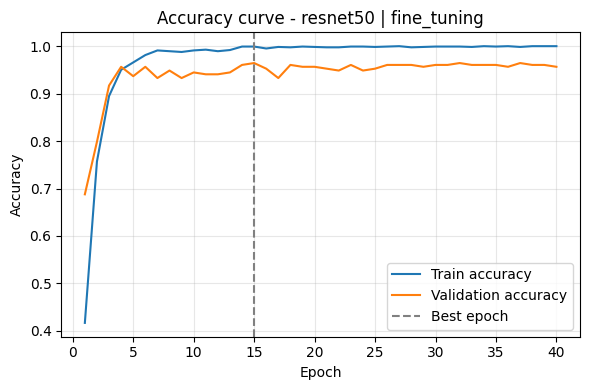

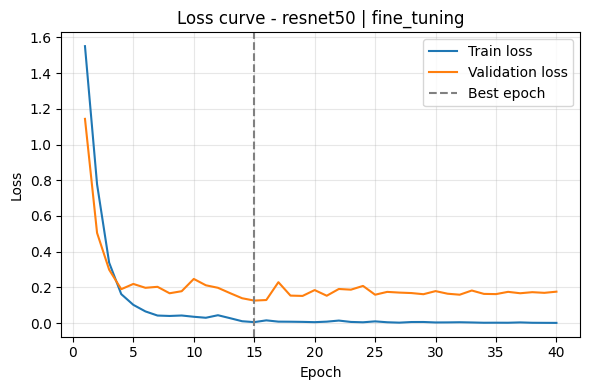

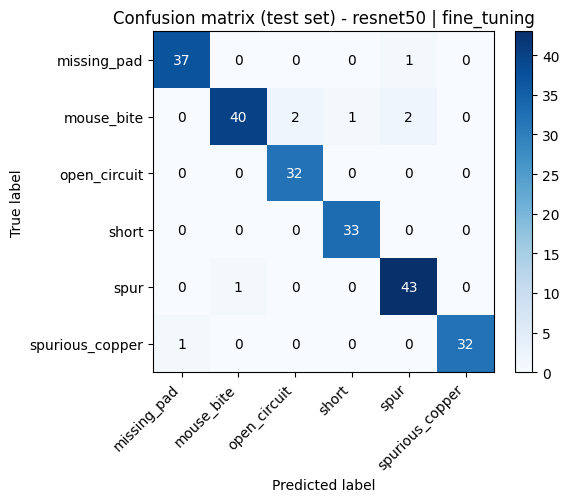

Classification report (test set):
                 precision    recall  f1-score   support

    missing_pad      0.974     0.974     0.974        38
     mouse_bite      0.976     0.889     0.930        45
   open_circuit      0.941     1.000     0.970        32
          short      0.971     1.000     0.985        33
           spur      0.935     0.977     0.956        44
spurious_copper      1.000     0.970     0.985        33

       accuracy                          0.964       225
      macro avg      0.966     0.968     0.966       225
   weighted avg      0.965     0.964     0.964       225

Accuracy  : 0.9644
Precision : 0.9660 (macro)
Recall    : 0.9683 (macro)
F1-score  : 0.9665 (macro)
Training time: 73.1 seconds
Testing time : 0.288 seconds (1.28 ms per image)

####################################################################################################
MODEL: efficientnet_b0    MODE: feature_extraction
Settings: dropout=0.2, weight_decay=1e-05, lr_scale=3.0 | Best 

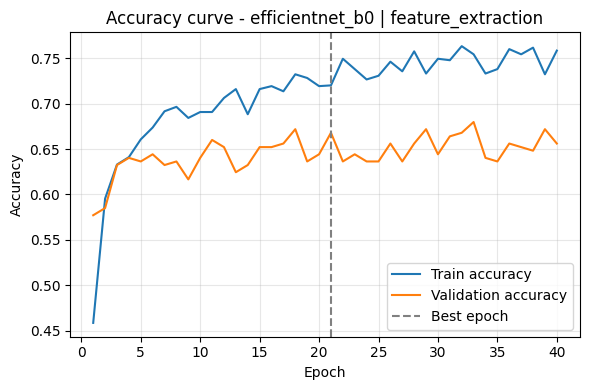

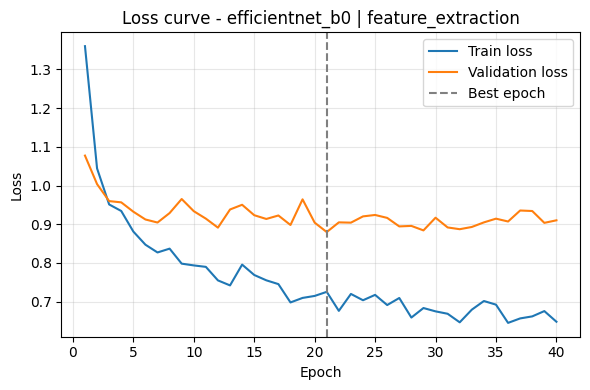

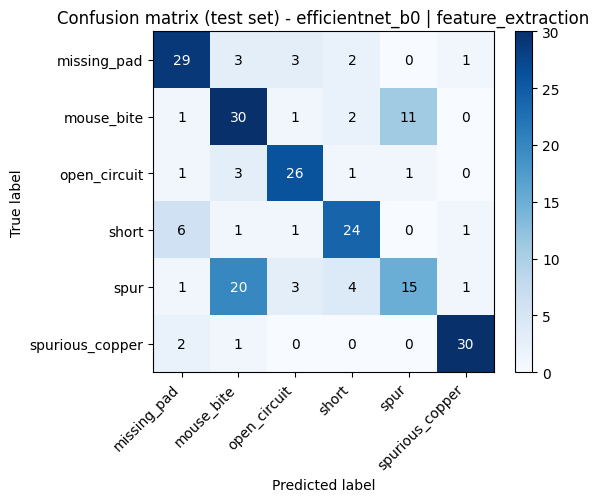

Classification report (test set):
                 precision    recall  f1-score   support

    missing_pad      0.725     0.763     0.744        38
     mouse_bite      0.517     0.667     0.583        45
   open_circuit      0.765     0.812     0.788        32
          short      0.727     0.727     0.727        33
           spur      0.556     0.341     0.423        44
spurious_copper      0.909     0.909     0.909        33

       accuracy                          0.684       225
      macro avg      0.700     0.703     0.695       225
   weighted avg      0.683     0.684     0.677       225

Accuracy  : 0.6844
Precision : 0.6998 (macro)
Recall    : 0.7033 (macro)
F1-score  : 0.6955 (macro)
Training time: 71.5 seconds
Testing time : 0.271 seconds (1.21 ms per image)

####################################################################################################
MODEL: efficientnet_b0    MODE: fine_tuning
Settings: dropout=0.4, weight_decay=0.0001, lr_scale=1.0 | Best epoch:

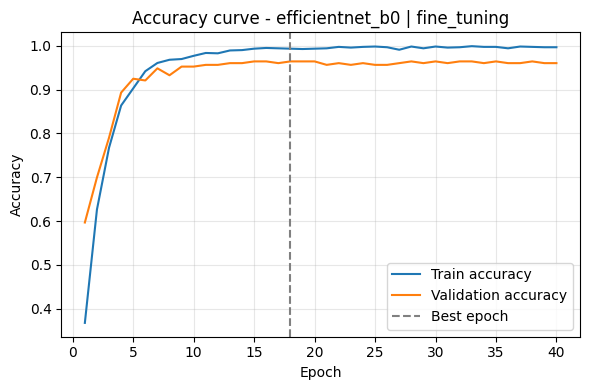

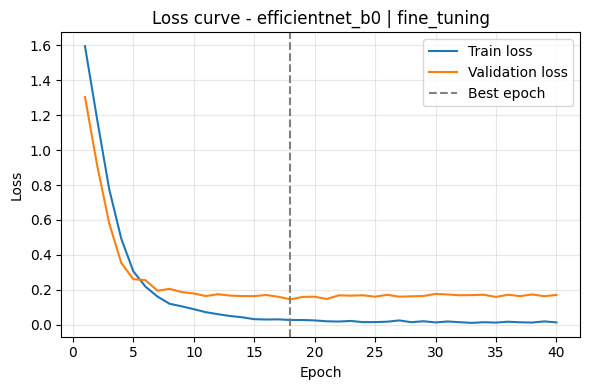

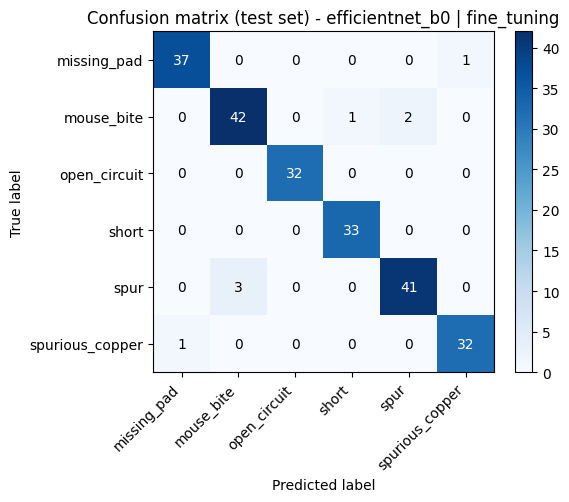

Classification report (test set):
                 precision    recall  f1-score   support

    missing_pad      0.974     0.974     0.974        38
     mouse_bite      0.933     0.933     0.933        45
   open_circuit      1.000     1.000     1.000        32
          short      0.971     1.000     0.985        33
           spur      0.953     0.932     0.943        44
spurious_copper      0.970     0.970     0.970        33

       accuracy                          0.964       225
      macro avg      0.967     0.968     0.967       225
   weighted avg      0.964     0.964     0.964       225

Accuracy  : 0.9644
Precision : 0.9668 (macro)
Recall    : 0.9681 (macro)
F1-score  : 0.9674 (macro)
Training time: 72.7 seconds
Testing time : 0.274 seconds (1.22 ms per image)

####################################################################################################
MODEL: mobilenet_v2    MODE: feature_extraction
Settings: dropout=0.2, weight_decay=1e-05, lr_scale=3.0 | Best epo

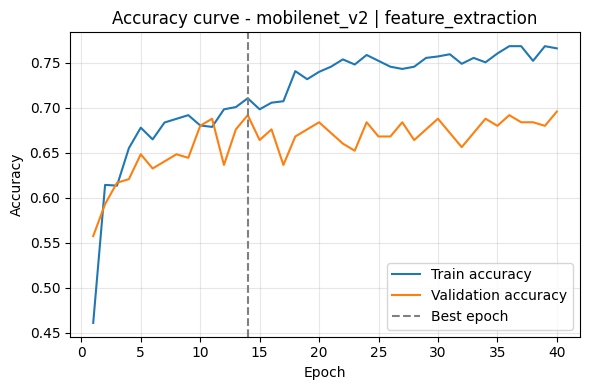

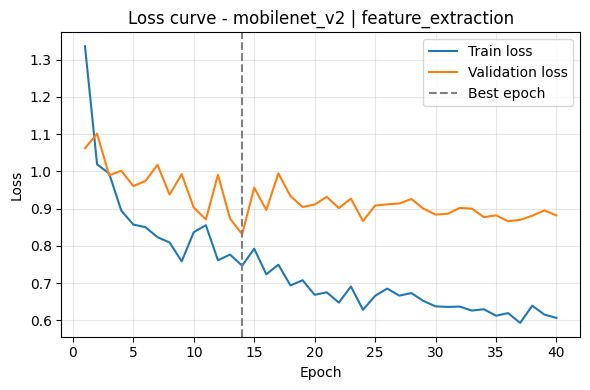

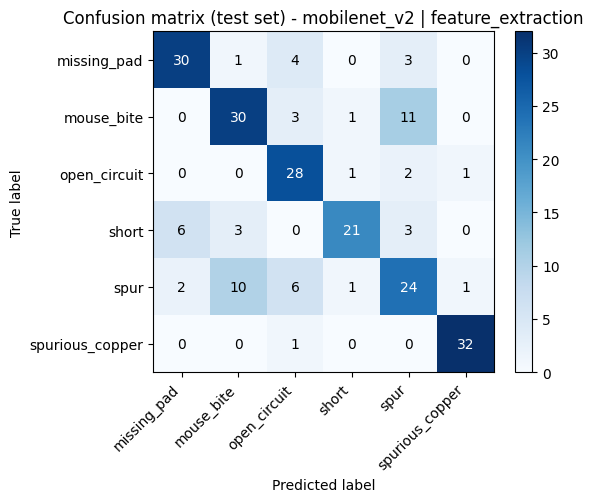

Classification report (test set):
                 precision    recall  f1-score   support

    missing_pad      0.789     0.789     0.789        38
     mouse_bite      0.682     0.667     0.674        45
   open_circuit      0.667     0.875     0.757        32
          short      0.875     0.636     0.737        33
           spur      0.558     0.545     0.552        44
spurious_copper      0.941     0.970     0.955        33

       accuracy                          0.733       225
      macro avg      0.752     0.747     0.744       225
   weighted avg      0.740     0.733     0.732       225

Accuracy  : 0.7333
Precision : 0.7520 (macro)
Recall    : 0.7471 (macro)
F1-score  : 0.7440 (macro)
Training time: 71.2 seconds
Testing time : 0.270 seconds (1.20 ms per image)

####################################################################################################
MODEL: mobilenet_v2    MODE: fine_tuning
Settings: dropout=0.4, weight_decay=0.0001, lr_scale=1.0 | Best epoch: 23

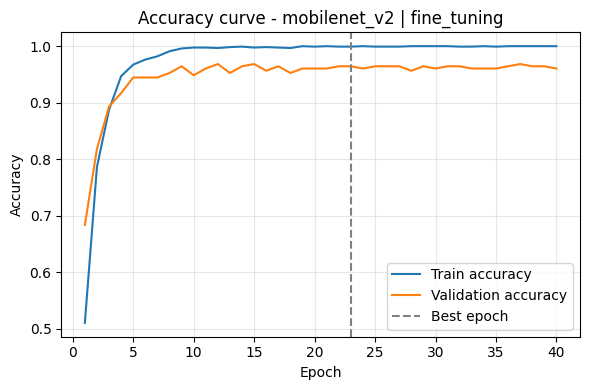

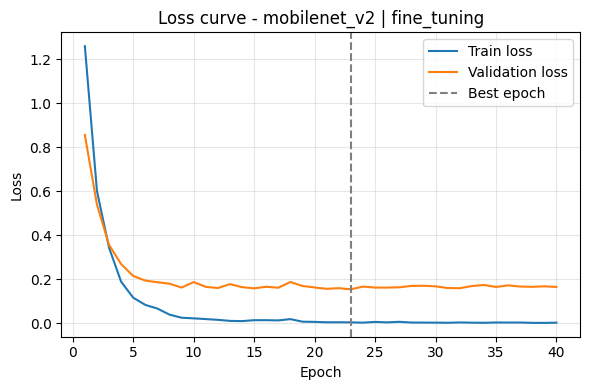

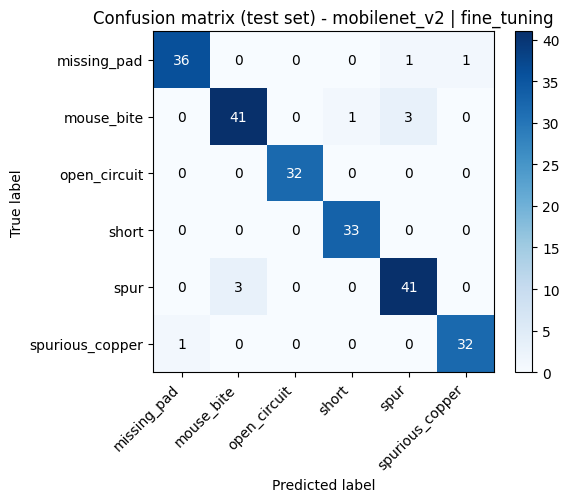

Classification report (test set):
                 precision    recall  f1-score   support

    missing_pad      0.973     0.947     0.960        38
     mouse_bite      0.932     0.911     0.921        45
   open_circuit      1.000     1.000     1.000        32
          short      0.971     1.000     0.985        33
           spur      0.911     0.932     0.921        44
spurious_copper      0.970     0.970     0.970        33

       accuracy                          0.956       225
      macro avg      0.959     0.960     0.960       225
   weighted avg      0.956     0.956     0.955       225

Accuracy  : 0.9556
Precision : 0.9594 (macro)
Recall    : 0.9600 (macro)
F1-score  : 0.9596 (macro)
Training time: 72.1 seconds
Testing time : 0.265 seconds (1.18 ms per image)



In [ ]:
for run_name in results.keys():
    result = results[run_name]
    test_result = test_results[run_name]
    title = result["model_name"] + " | " + result["mode"]

    print("#" * 100)
    print("MODEL:", result["model_name"], "   MODE:", result["mode"])
    print("Settings:", result["settings"], "| Best epoch:", result["best_epoch"] + 1, "of", EPOCHS)
    print("#" * 100)

    plot_accuracy_curve(result, title)
    plot_loss_curve(result, title)
    plot_confusion_matrix(test_result["cm"], title)

    print("Classification report (test set):")
    print(test_result["report"])
    print("Accuracy  : %.4f" % test_result["accuracy"])
    print("Precision : %.4f (macro)" % test_result["precision"])
    print("Recall    : %.4f (macro)" % test_result["recall"])
    print("F1-score  : %.4f (macro)" % test_result["f1"])
    print("Training time: %.1f seconds" % result["train_time"])
    print("Testing time : %.3f seconds (%.2f ms per image)" % (test_result["test_time"], test_result["ms_per_image"]))
    print()

    # save the report as a text file
    with open(RESULTS_DIR / (run_name + "_classification_report.txt"), "w") as f:
        f.write(test_result["report"])

# 9. Summary table (all 6 runs)

In [ ]:
summary_rows = []
for run_name in results.keys():
    result = results[run_name]
    test_result = test_results[run_name]
    summary_rows.append({
        "Model": result["model_name"],
        "Mode": result["mode"],
        "Best epoch": result["best_epoch"] + 1,
        "Accuracy": round(test_result["accuracy"], 4),
        "Precision": round(test_result["precision"], 4),
        "Recall": round(test_result["recall"], 4),
        "F1-score": round(test_result["f1"], 4),
        "Training time (s)": round(result["train_time"], 1),
        "Testing time (s)": round(test_result["test_time"], 3),
        "ms per image": round(test_result["ms_per_image"], 2),
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS_DIR / "summary_table.csv", index=False)
summary

,Model,Mode,Best epoch,Accuracy,Precision,Recall,F1-score,Training time (s),Testing time (s),ms per image
0,resnet50,feature_extraction,37,0.7378,0.7447,0.7566,0.7472,72.9,0.291,1.29
1,resnet50,fine_tuning,15,0.9644,0.9660,0.9683,0.9665,73.1,0.288,1.28
2,efficientnet_b0,feature_extraction,21,0.6844,0.6998,0.7033,0.6955,71.5,0.271,1.21
3,efficientnet_b0,fine_tuning,18,0.9644,0.9668,0.9681,0.9674,72.7,0.274,1.22
4,mobilenet_v2,feature_extraction,14,0.7333,0.7520,0.7471,0.7440,71.2,0.270,1.20
5,mobilenet_v2,fine_tuning,23,0.9556,0.9594,0.9600,0.9596,72.1,0.265,1.18


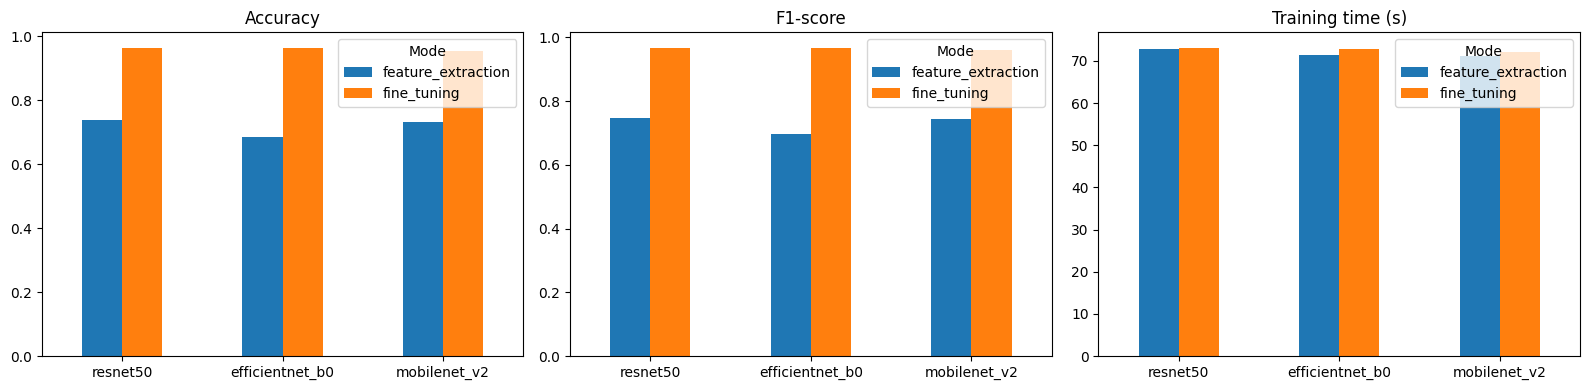

Best result: efficientnet_b0 | fine_tuning | accuracy 0.9644 | F1 0.9674

Effect of fine-tuning on F1-score (fine_tuning minus feature_extraction):
  resnet50         without FT: 0.7472 | with FT: 0.9665 | difference: +0.2193
  efficientnet_b0  without FT: 0.6955 | with FT: 0.9674 | difference: +0.2719
  mobilenet_v2     without FT: 0.7440 | with FT: 0.9596 | difference: +0.2156


In [ ]:
# compare the models in bar charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
metrics = ["Accuracy", "F1-score", "Training time (s)"]
for k in range(3):
    table = summary.pivot(index="Model", columns="Mode", values=metrics[k])
    table = table.loc[MODEL_NAMES]
    table.plot(kind="bar", ax=axes[k], rot=0)
    axes[k].set_title(metrics[k])
    axes[k].set_xlabel("")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparison_charts.png", dpi=100)
plt.show()

best_row = summary.sort_values("F1-score", ascending=False).iloc[0]
print("Best result:", best_row["Model"], "|", best_row["Mode"],
      "| accuracy", best_row["Accuracy"], "| F1", best_row["F1-score"])

print()
print("Effect of fine-tuning on F1-score (fine_tuning minus feature_extraction):")
for model_name in MODEL_NAMES:
    f1_fe = summary[(summary["Model"] == model_name) & (summary["Mode"] == "feature_extraction")]["F1-score"].iloc[0]
    f1_ft = summary[(summary["Model"] == model_name) & (summary["Mode"] == "fine_tuning")]["F1-score"].iloc[0]
    print("  %-16s without FT: %.4f | with FT: %.4f | difference: %+.4f" % (model_name, f1_fe, f1_ft, f1_ft - f1_fe))

# 10. Conclusion
- Three pretrained CNNs (ResNet-50, EfficientNet-B0, MobileNetV2) were trained for 40 epochs, **without fine-tuning** (frozen backbone) and **with fine-tuning** (all layers).
- Overfitting and underfitting were checked for every run (Section 6) and fixed by re-training when a problem was found.
- Accuracy, precision, recall, F1, confusion matrix, per-class classification report, training time and testing time are reported for every model and mode.
- Fine-tuning usually helps because ImageNet features describe natural objects, while PCB defects are tiny changes of copper traces. The summary table shows the exact difference for our runs.
- The test set is small, so differences of 1–2 points between models can be noise. The patches are cut around the real defect boxes, so these results measure defect-type recognition, not full-board defect detection.

# 11. Download the results
This cell puts all plots, reports and tables into one ZIP file and downloads it to your computer.
**Before pushing to GitHub:** File → Save a copy in GitHub (or File → Download → Download .ipynb), with all outputs visible.

In [ ]:
shutil.make_archive("submission2_results", "zip", RESULTS_DIR)
print("Created submission2_results.zip")

try:
    from google.colab import files
    files.download("submission2_results.zip")
except Exception as e:
    print("Download works only inside Google Colab. The file is saved as submission2_results.zip:", e)

Created submission2_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>